# D1 – Régularisation et généralisation
Comparaison de quatre cas, avec les courbes **loss train et validation en fonction des époques** :
1. sans régularisation ; 2. $L^2$ ; 3. Dropout ; 4. Early stopping.

**Protocole.** Même architecture $2\to16\to8\to1$, même split, mêmes seeds (0 à 4, qui fixent l'initialisation des poids et l'ordre des mini-batchs). Optimiseur : Adam, $\alpha=0.003$ (meilleur lr trouvé sur la validation en C2). Budget : 500 époques, batch de 32 — assez long pour que le sur-apprentissage apparaisse (à 100 époques il est à peine visible).



**Rappels.**
- $L^2$ : $F_\lambda(\theta)=F_{train}(\theta)+\frac\lambda2\sum_\ell\|W^{(\ell)}\|_F^2$, biais non pénalisés, d'où $\nabla_{W^{(\ell)}}F_\lambda=\nabla_{W^{(\ell)}}F_{train}+\lambda W^{(\ell)}$.
- Dropout : $M_j\sim\mathrm{Bernoulli}(p)$, $\tilde h_j=\frac{M_j}{p}h_j$ ; $p$ est la probabilité de **garder** une unité, donc taux de dropout $=1-p$. Désactivé en validation/test.
- Early stopping : on garde les meilleurs paramètres selon la loss val, on arrête après $P$ époques sans amélioration, puis on restaure les meilleurs paramètres.

In [2]:
%load_ext autoreload
%autoreload 2

import os, pickle, sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data
from src.model import MLP
from src.layers import Dropout
from src.losses import bce
from src.optimizers import Adam
from src.train import train
from src.regularization import EarlyStopping, l2_penalty, add_l2_grad
from src.plots import plot_mean_std

DATA_SEED = 42
EPOCHS, BATCH, LR = 500, 32, 0.003
SEEDS = range(5)
LAMBDAS = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]     # liste du sujet
DROP_RATES = [0.1, 0.2, 0.3, 0.5]               # taux de dropout = 1 - p
PATIENCE = 20                                   # fixée a priori (sensibilité étudiée plus bas)
data = load_data(seed=DATA_SEED)

def run(seed, l2=0.0, drop_rate=0.0, early_stopping=None):
    model = MLP(seed=seed, drop_rate=drop_rate)
    return train(model, Adam(lr=LR), data, epochs=EPOCHS, batch_size=BATCH, seed=seed,
                 l2=l2, early_stopping=early_stopping)

## 0. Tests unitaires des briques de régularisation

In [3]:
# (a) Gradient de F_lambda = F_train + (lambda/2) sum ||W||^2 : vérification par différences finies
m = MLP(seed=1); X, y = data["X_train"][:40], data["y_train"][:40]; lam = 0.1
m.loss_and_grad(X, y); add_l2_grad(m, lam); g_a = m.get_grads().copy()

theta = m.get_params(); g_n = np.zeros_like(theta)
def F(t):
    m.set_params(t); return bce(m.forward(X), y) + l2_penalty(m, lam)
for j in range(theta.size):
    e = np.zeros_like(theta); e[j] = 1e-5
    g_n[j] = (F(theta + e) - F(theta - e)) / 2e-5
err = np.linalg.norm(g_a - g_n) / (np.linalg.norm(g_a) + np.linalg.norm(g_n) + 1e-12)
print(f"gradient L2 : erreur relative = {err:.2e}"); assert err < 1e-6

gradient L2 : erreur relative = 9.68e-11


In [4]:
# (b) Dropout : identité en mode eval, aléatoire en mode train, moyenne conservée (mise à l'échelle 1/p)
m = MLP(seed=0, drop_rate=0.3)
print([type(l).__name__ for l in m.layers])
Xb = data["X_train"][:5]
m.eval();  assert np.allclose(m.forward(Xb), m.forward(Xb))          # déterministe
m.train(); assert not np.allclose(m.forward(Xb), m.forward(Xb))      # aléatoire
m.eval()

dp = Dropout(p=0.8, rng=np.random.default_rng(0)); dp.training = True
out = dp.forward(np.ones((100000, 4)))
print("moyenne après dropout  :", out.mean().round(4), "| valeurs :", np.unique(out))
dp.training = False; assert np.array_equal(dp.forward(np.ones((3, 2))), np.ones((3, 2)))

# l'initialisation des poids ne dépend pas du dropout (comparaison équitable)
assert np.allclose(MLP(seed=0).get_params(), MLP(seed=0, drop_rate=0.3).get_params())
print("Dropout OK")

['Linear', 'ReLU', 'Dropout', 'Linear', 'ReLU', 'Dropout', 'Linear', 'Sigmoid']
moyenne après dropout  : 1.0005 | valeurs : [0.   1.25]
Dropout OK


In [5]:
# (c) Early stopping sur une suite de losses connue : patience = 3
es = EarlyStopping(patience=3)
vals = [1.0, 0.9, 0.8, 0.85, 0.86, 0.87, 0.5]
stop_at = None
for ep, v in enumerate(vals):
    if es.step(v, np.array([float(ep)]), ep):
        stop_at = ep; break
print("arrêt à l'époque", stop_at, "| meilleure époque", es.best_epoch, "| paramètres sauvegardés", es.best_params)
assert stop_at == 5 and es.best_epoch == 2 and es.best_params[0] == 2.0
print("Early stopping OK")

arrêt à l'époque 5 | meilleure époque 2 | paramètres sauvegardés [2.]
Early stopping OK


## 1. Sans régularisation : détection du sur-apprentissage
On entraîne 500 époques et on regarde où la loss val est minimale, puis ce qui se passe ensuite.

In [6]:
results = {}                                    # (cas, hyperparamètre, seed) -> historique

for s in SEEDS:
    results[("L2", 0, s)] = run(s)              # lambda = 0 : sans régularisation

rows = []
for s in SEEDS:
    h = results[("L2", 0, s)]; lv = np.array(h["loss_val"]); lt = np.array(h["loss_train"])
    rows.append({"seed": s, "époque min val": int(lv.argmin()), "val min": lv.min(),
                 "val finale": lv[-1], "train final": lt[-1], "remontée val": lv[-1] - lv.min()})
over = pd.DataFrame(rows).set_index("seed")
print(over.round(4)); print()
print(f"Époque du minimum de la loss val : {over['époque min val'].mean():.0f} en moyenne "
      f"(min {over['époque min val'].min()}, max {over['époque min val'].max()})")
print(f"Remontée moyenne de la loss val après son minimum : +{over['remontée val'].mean():.4f}")

      époque min val  val min  val finale  train final  remontée val
seed                                                                
0                234   0.0860      0.0949       0.0714        0.0089
1                 69   0.0884      0.1156       0.0688        0.0272
2                186   0.0795      0.0954       0.0666        0.0159
3                 51   0.0899      0.1127       0.0693        0.0228
4                 96   0.0800      0.1041       0.0628        0.0241

Époque du minimum de la loss val : 127 en moyenne (min 51, max 234)
Remontée moyenne de la loss val après son minimum : +0.0198


## 2. Régularisation $L^2$ : balayage de $\lambda$

In [7]:
for lam in LAMBDAS[1:]:
    for s in SEEDS:
        results[("L2", lam, s)] = run(s, l2=lam)

def final_row(h, e=-1):
    lt, lv = h["loss_train"][e], h["loss_val"][e]
    return {"loss_train": lt, "loss_val": lv, "acc_val": h["acc_val"][e], "gap": lv - lt, "norme_theta": h["weight_norm"][e]}

l2_rows = []
for lam in LAMBDAS:
    for s in SEEDS:
        r = final_row(results[("L2", lam, s)]); r.update(lam=lam, seed=s); l2_rows.append(r)
l2_df = pd.DataFrame(l2_rows)
l2_tab = l2_df.groupby("lam").agg(loss_train=("loss_train", "mean"), loss_val=("loss_val", "mean"),
                                  loss_val_std=("loss_val", "std"), acc_val=("acc_val", "mean"),
                                  gap=("gap", "mean"), norme_theta=("norme_theta", "mean"))
lam_star = l2_tab["loss_val"].idxmin()
print("lambda retenu (min de la loss val finale moyenne) :", lam_star)
l2_tab.round(4)

lambda retenu (min de la loss val finale moyenne) : 0.001


,loss_train,loss_val,loss_val_std,acc_val,gap,norme_theta
lam,,,,,,
0.00000,0.0678,0.1045,0.0095,0.9640,0.0367,15.2555
0.00001,0.0678,0.0973,0.0076,0.9653,0.0295,13.4495
0.00010,0.0721,0.0903,0.0079,0.9660,0.0183,9.8564
0.00100,0.0800,0.0857,0.0030,0.9673,0.0057,6.7664
0.01000,0.1201,0.1226,0.0003,0.9567,0.0025,4.8564
0.10000,0.3356,0.3259,0.0026,0.8780,-0.0097,1.9806


## 3. Dropout : balayage du taux

In [8]:
for p in DROP_RATES:
    for s in SEEDS:
        results[("Dropout", p, s)] = run(s, drop_rate=p)

dp_rows = []
for p in [0.0] + DROP_RATES:
    for s in SEEDS:
        h = results[("L2", 0, s)] if p == 0.0 else results[("Dropout", p, s)]
        r = final_row(h); r.update(taux=p, seed=s); dp_rows.append(r)
dp_df = pd.DataFrame(dp_rows)
dp_tab = dp_df.groupby("taux").agg(loss_train=("loss_train", "mean"), loss_val=("loss_val", "mean"),
                                   loss_val_std=("loss_val", "std"), acc_val=("acc_val", "mean"),
                                   gap=("gap", "mean"), norme_theta=("norme_theta", "mean"))
p_star = dp_tab.loc[DROP_RATES, "loss_val"].idxmin()
print("taux de dropout retenu (min de la loss val finale moyenne) :", p_star)
dp_tab.round(4)

taux de dropout retenu (min de la loss val finale moyenne) : 0.1


,loss_train,loss_val,loss_val_std,acc_val,gap,norme_theta
taux,,,,,,
0.0,0.0678,0.1045,0.0095,0.9640,0.0367,15.2555
0.1,0.0684,0.0977,0.0054,0.9640,0.0292,18.4669
0.2,0.0779,0.0995,0.0074,0.9640,0.0216,18.3137
0.3,0.0875,0.1062,0.0076,0.9627,0.0186,17.8867
0.5,0.1428,0.1528,0.0125,0.9427,0.0101,14.8360


## 4. Early stopping
Patience $P=20$ fixée à l'avance (la choisir sur la loss val favoriserait mécaniquement les grandes valeurs, puisque la « meilleure » loss val est un minimum pris sur plus d'époques). On regarde aussi la sensibilité à $P$.

In [9]:
for s in SEEDS:
    results[("ES", PATIENCE, s)] = run(s, early_stopping=EarlyStopping(patience=PATIENCE))

pat_rows = []
for P in [5, 10, 20, 50]:
    for s in SEEDS:
        h = results[("ES", P, s)] if P == PATIENCE else run(s, early_stopping=EarlyStopping(patience=P))
        results[("ES", P, s)] = h
        be = h["meta"]["best_epoch"]
        pat_rows.append({"P": P, "seed": s, "époque retenue": be, "époques effectuées": h["meta"]["epochs_run"],
                         "loss val retenue": h["loss_val"][be], "loss train retenue": h["loss_train"][be]})
pat_df = pd.DataFrame(pat_rows)
pat_df.groupby("P").agg(epoque_retenue=("époque retenue", "mean"), epoques_effectuees=("époques effectuées", "mean"),
                        loss_val=("loss val retenue", "mean"), loss_train=("loss train retenue", "mean")).round(4)

,epoque_retenue,epoques_effectuees,loss_val,loss_train
P,,,,
5,57.4,62.4,0.0864,0.0807
10,59.8,69.8,0.0860,0.0806
20,71.4,91.4,0.0855,0.0793
50,95.2,145.2,0.0852,0.0777


## 5. Figure D1 : loss train et validation en fonction des époques
Pour les cas 1 à 3 : moyenne ± écart-type sur les 5 seeds. Pour l'early stopping, les arrêts surviennent à des époques différentes selon la seed, on trace donc chaque seed (étoile = époque retenue).

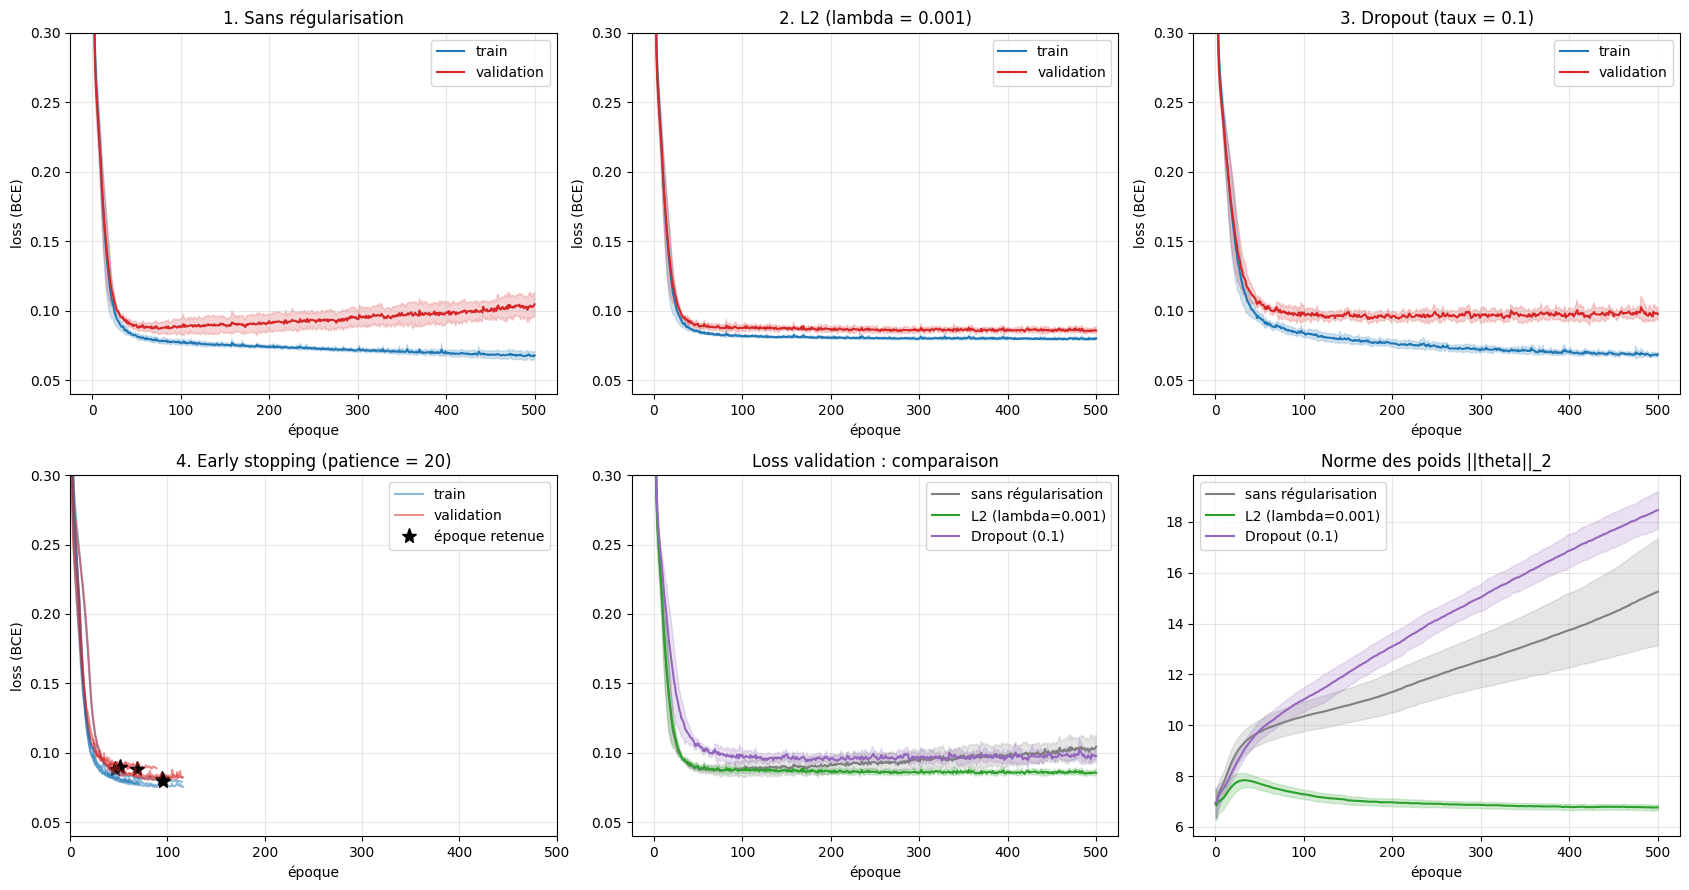

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
ylim = (0.04, 0.30)

def panel(a, hs, title):
    plot_mean_std(a, hs, "loss_train", "train", "tab:blue")
    plot_mean_std(a, hs, "loss_val", "validation", "tab:red")
    a.set_title(title); a.set_xlabel("époque"); a.set_ylabel("loss (BCE)"); a.set_ylim(*ylim); a.grid(alpha=.3); a.legend()

H_none = [results[("L2", 0, s)] for s in SEEDS]
H_l2   = [results[("L2", lam_star, s)] for s in SEEDS]
H_dp   = [results[("Dropout", p_star, s)] for s in SEEDS]
H_es   = [results[("ES", PATIENCE, s)] for s in SEEDS]

panel(ax[0, 0], H_none, "1. Sans régularisation")
panel(ax[0, 1], H_l2, f"2. L2 (lambda = {lam_star:g})")
panel(ax[0, 2], H_dp, f"3. Dropout (taux = {p_star:g})")

a = ax[1, 0]
for i, h in enumerate(H_es):
    a.plot(h["loss_train"], color="tab:blue", alpha=.5, label="train" if i == 0 else None)
    a.plot(h["loss_val"], color="tab:red", alpha=.5, label="validation" if i == 0 else None)
    be = h["meta"]["best_epoch"]
    a.plot(be, h["loss_val"][be], "k*", ms=11, label="époque retenue" if i == 0 else None)
a.set_title(f"4. Early stopping (patience = {PATIENCE})"); a.set_xlabel("époque"); a.set_ylabel("loss (BCE)")
a.set_ylim(*ylim); a.set_xlim(0, EPOCHS); a.grid(alpha=.3); a.legend()

# comparaison des loss de validation
for hs, lab, c in [(H_none, "sans régularisation", "gray"), (H_l2, f"L2 (lambda={lam_star:g})", "tab:green"),
                   (H_dp, f"Dropout ({p_star:g})", "tab:purple")]:
    plot_mean_std(ax[1, 1], hs, "loss_val", lab, c)
ax[1, 1].set_title("Loss validation : comparaison"); ax[1, 1].set_xlabel("époque")
ax[1, 1].set_ylim(*ylim); ax[1, 1].grid(alpha=.3); ax[1, 1].legend()

for hs, lab, c in [(H_none, "sans régularisation", "gray"), (H_l2, f"L2 (lambda={lam_star:g})", "tab:green"),
                   (H_dp, f"Dropout ({p_star:g})", "tab:purple")]:
    plot_mean_std(ax[1, 2], hs, "weight_norm", lab, c)
ax[1, 2].set_title("Norme des poids ||theta||_2"); ax[1, 2].set_xlabel("époque"); ax[1, 2].grid(alpha=.3); ax[1, 2].legend()

plt.tight_layout(); os.makedirs("../results/figures", exist_ok=True)
fig.savefig("../results/figures/d1_curves.png", dpi=150); plt.show()

## 6. Tableau comparatif (validation uniquement)
Pour les cas sans early stopping, les valeurs sont celles de la dernière époque ; pour l'early stopping, celles de l'époque retenue.

In [11]:
def ms(x, d=4): return f"{np.mean(x):.{d}f} ± {np.std(x, ddof=1):.{d}f}"

def collect(hs, selected_epoch=None):
    out = []
    for h in hs:
        e = -1 if selected_epoch is None else h["meta"]["best_epoch"]
        out.append(final_row(h, e))
    return pd.DataFrame(out)

cases = {
    "Sans régularisation": (H_none, None, "-"),
    f"L2": (H_l2, None, f"lambda = {lam_star:g}"),
    f"Dropout": (H_dp, None, f"taux = {p_star:g}"),
    "Early stopping": (H_es, "es", f"P = {PATIENCE}"),
}
rows = []
for name, (hs, sel, hp) in cases.items():
    c = collect(hs, sel)
    rows.append({"cas": name, "hyperparamètre": hp,
                 "époque retenue": ms([h["meta"]["best_epoch"] if sel else EPOCHS for h in hs], 0) if sel else str(EPOCHS),
                 "loss train": ms(c.loss_train), "loss val": ms(c.loss_val), "acc val": ms(c.acc_val, 3),
                 "écart val-train": ms(c.gap), "||theta||": ms(c.norme_theta, 2)})
table = pd.DataFrame(rows).set_index("cas")
table

,hyperparamètre,époque retenue,loss train,loss val,acc val,écart val-train,||theta||
cas,,,,,,,
Sans régularisation,-,500,0.0678 ± 0.0033,0.1045 ± 0.0095,0.964 ± 0.004,0.0367 ± 0.0100,15.26 ± 2.34
L2,lambda = 0.001,500,0.0800 ± 0.0007,0.0857 ± 0.0030,0.967 ± 0.003,0.0057 ± 0.0034,6.77 ± 0.12
Dropout,taux = 0.1,500,0.0684 ± 0.0018,0.0977 ± 0.0054,0.964 ± 0.005,0.0292 ± 0.0053,18.47 ± 0.82
Early stopping,P = 20,71 ± 24,0.0793 ± 0.0024,0.0855 ± 0.0046,0.965 ± 0.006,0.0062 ± 0.0046,10.00 ± 0.68


In [12]:
# Sauvegarde pour D2 et la synthèse (notebook 10)
os.makedirs("../results", exist_ok=True)
table.to_csv("../results/d1_table.csv")
l2_tab.round(6).to_csv("../results/d1_l2_sweep.csv"); dp_tab.round(6).to_csv("../results/d1_dropout_sweep.csv")
pat_df.to_csv("../results/d1_patience.csv", index=False)
with open("../results/d1_histories.pkl", "wb") as f:
    pickle.dump({"lam_star": lam_star, "p_star": p_star, "patience": PATIENCE, "results": results}, f)
print("Sauvegardé dans ../results/")

Sauvegardé dans ../results/


## Bilan D1
*(les chiffres ci-dessous correspondent aux seeds et à la configuration de ce notebook ; relire si on les modifie)*

- **Sans régularisation**, la loss val atteint son minimum vers l'époque 130 en moyenne, puis remonte (≈ +0.02) alors que la loss train continue de baisser : c'est du **sur-apprentissage**, avec un écart val − train final d'environ 0.037.
- **$L^2$** : $\lambda=10^{-3}$ donne la meilleure loss val finale (≈ 0.086 contre ≈ 0.104), un écart val − train divisé par plus de 6 et une norme des poids réduite de plus de moitié. Trop fort ($\lambda\ge10^{-2}$), le modèle **sous-apprend** : la loss train elle-même remonte.
- **Dropout** : le meilleur taux de la grille est 0.1 ; il réduit un peu l'écart, mais moins bien que $L^2$ sur ce problème, et les taux élevés (0.5) sous-apprennent.
- **Early stopping** : le modèle retenu apparaît entre l'époque ≈ 45 et ≈ 95 selon la seed (patience 20), pour une loss val proche de celle de $L^2$. Attention : sa loss val est un *minimum choisi sur la validation* donc légèrement optimiste ; la comparaison honnête passera par le test, évalué une seule fois en D2.

# D2 – Analyse et évaluation finale

On analyse dans l'ordre :

1. la présence ou l'absence de sur-apprentissage ;
2. l'effet de $\lambda$ ;
3. l'effet du taux de dropout ;
4. l'époque choisie par l'early stopping ;
5. la performance finale sur le jeu de test.

Les points 1 à 4 utilisent **uniquement** le train et la validation, à partir des historiques de D1 (`results`). Le test n'apparaît qu'au point 5, une seule fois.

## 1. Sur-apprentissage sans régularisation
On suit l'écart val − train et l'accuracy de validation au cours de l'entraînement.

In [13]:
H_none = [results[("L2", 0, s)] for s in SEEDS]
LT = np.array([h["loss_train"] for h in H_none]); LV = np.array([h["loss_val"] for h in H_none])
AV = np.array([h["acc_val"] for h in H_none])
check = [50, 100, 200, 300, 500]
off = 0 if LV.shape[1] == EPOCHS + 1 else -1      # colonne de l'époque e (0 si l'état initial est enregistré)
of_tab = pd.DataFrame({"époque": check,
                       "loss train": [LT[:, e + off].mean() for e in check],
                       "loss val": [LV[:, e + off].mean() for e in check],
                       "écart val - train": [(LV - LT)[:, e + off].mean() for e in check],
                       "acc val": [AV[:, e + off].mean() for e in check]}).set_index("époque")
best_ep = LV.argmin(1) - off                         # numéro d'époque du minimum
print(f"Minimum de la loss val : époque {best_ep.mean():.0f} en moyenne (de {best_ep.min()} à {best_ep.max()} selon la seed)")
print(f"Seeds où la loss val finale dépasse son minimum de plus de 0.005 : {(LV[:, -1] - LV.min(1) > 0.005).sum()}/5")
of_tab.round(4)

Minimum de la loss val : époque 127 en moyenne (de 51 à 234 selon la seed)
Seeds où la loss val finale dépasse son minimum de plus de 0.005 : 5/5


,loss train,loss val,écart val - train,acc val
époque,,,,
50,0.0819,0.0895,0.0076,0.9660
100,0.0768,0.0880,0.0112,0.9653
200,0.0742,0.0925,0.0182,0.9633
300,0.0716,0.0940,0.0224,0.9627
500,0.0678,0.1045,0.0367,0.9640


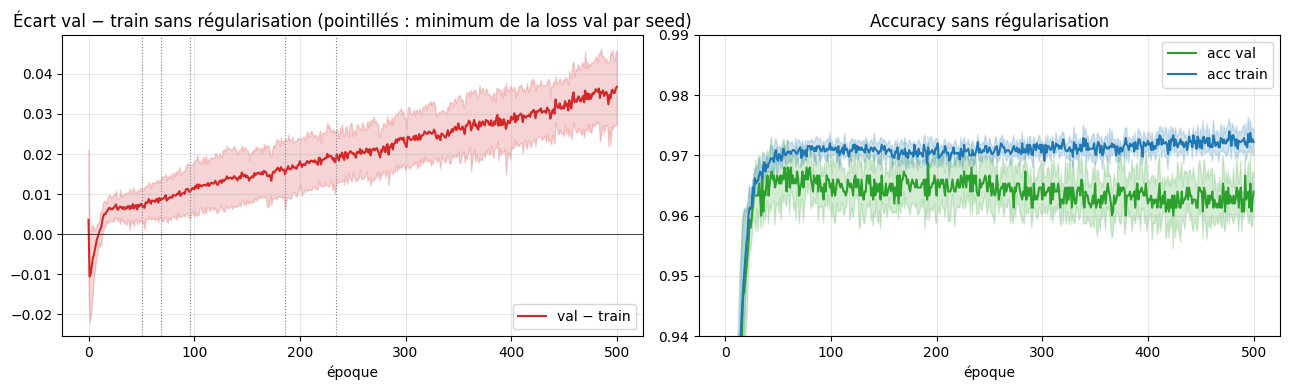

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_mean_std(ax[0], [{"gap": list(lv - lt)} for lv, lt in zip(LV, LT)], "gap", "val − train", "tab:red")
ax[0].axhline(0, color="k", lw=.5)
for e in best_ep:
    ax[0].axvline(e, color="gray", ls=":", lw=.8)
ax[0].set(title="Écart val − train sans régularisation (pointillés : minimum de la loss val par seed)", xlabel="époque")
plot_mean_std(ax[1], H_none, "acc_val", "acc val", "tab:green")
plot_mean_std(ax[1], H_none, "acc_train", "acc train", "tab:blue")
ax[1].set(title="Accuracy sans régularisation", xlabel="époque", ylim=(0.94, 0.99))
for a in ax: a.grid(alpha=.3); a.legend()
plt.tight_layout(); fig.savefig("../results/figures/d2_overfitting.png", dpi=150); plt.show()

## 2. Effet de $\lambda$

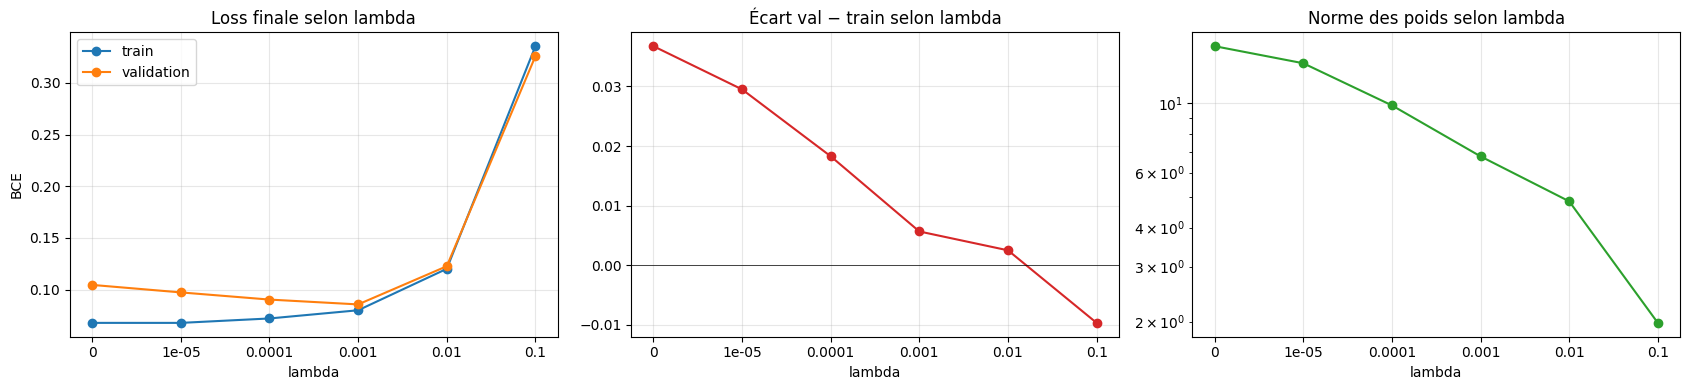

Écart val − train et norme diminuent quand lambda augmente : True (norme), True (écart)


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
xs = np.arange(len(LAMBDAS)); labels = ["0"] + [f"{l:g}" for l in LAMBDAS[1:]]
ax[0].plot(xs, l2_tab["loss_train"], "o-", label="train"); ax[0].plot(xs, l2_tab["loss_val"], "o-", label="validation")
ax[0].set(title="Loss finale selon lambda", ylabel="BCE")
ax[1].plot(xs, l2_tab["gap"], "o-", color="tab:red"); ax[1].axhline(0, color="k", lw=.5)
ax[1].set(title="Écart val − train selon lambda")
ax[2].plot(xs, l2_tab["norme_theta"], "o-", color="tab:green"); ax[2].set(title="Norme des poids selon lambda", yscale="log")
for a in ax:
    a.set_xticks(xs); a.set_xticklabels(labels); a.set_xlabel("lambda"); a.grid(alpha=.3)
ax[0].legend()
plt.tight_layout(); fig.savefig("../results/figures/d2_lambda.png", dpi=150); plt.show()
print("Écart val − train et norme diminuent quand lambda augmente :",
      bool(np.all(np.diff(l2_tab["norme_theta"]) < 0)), "(norme),", bool(np.all(np.diff(l2_tab["gap"]) < 0)), "(écart)")

## 3. Effet du taux de dropout

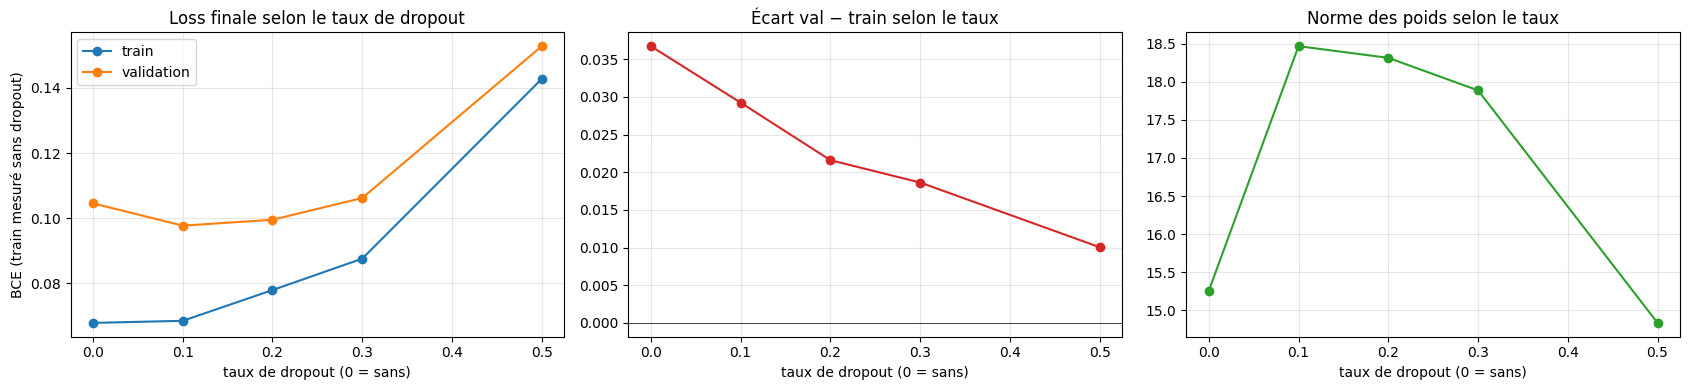

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
rates = dp_tab.index.values
ax[0].plot(rates, dp_tab["loss_train"], "o-", label="train"); ax[0].plot(rates, dp_tab["loss_val"], "o-", label="validation")
ax[0].set(title="Loss finale selon le taux de dropout", ylabel="BCE (train mesuré sans dropout)")
ax[1].plot(rates, dp_tab["gap"], "o-", color="tab:red"); ax[1].axhline(0, color="k", lw=.5)
ax[1].set(title="Écart val − train selon le taux")
ax[2].plot(rates, dp_tab["norme_theta"], "o-", color="tab:green"); ax[2].set(title="Norme des poids selon le taux")
for a in ax:
    a.set_xlabel("taux de dropout (0 = sans)"); a.grid(alpha=.3)
ax[0].legend()
plt.tight_layout(); fig.savefig("../results/figures/d2_dropout.png", dpi=150); plt.show()

## 4. Époque choisie par l'early stopping

In [17]:
H_es = [results[("ES", PATIENCE, s)] for s in SEEDS]
es_tab = pd.DataFrame({"seed": list(SEEDS),
                       "époque retenue": [h["meta"]["best_epoch"] for h in H_es],
                       "époques effectuées": [h["meta"]["epochs_run"] for h in H_es],
                       "loss val retenue": [h["loss_val"][h["meta"]["best_epoch"]] for h in H_es],
                       "minimum val sans régularisation (500 ép.)": LV.min(1),
                       "époque de ce minimum": best_ep}).set_index("seed")
be = es_tab["époque retenue"]
print(f"P = {PATIENCE} : époque retenue {be.mean():.0f} ± {be.std():.0f} (de {be.min()} à {be.max()}), "
      f"{es_tab['époques effectuées'].mean():.0f} époques effectuées sur {EPOCHS} possibles")
es_tab.round(4)

P = 20 : époque retenue 71 ± 24 (de 46 à 96), 91 époques effectuées sur 500 possibles


,époque retenue,époques effectuées,loss val retenue,minimum val sans régularisation (500 ép.),époque de ce minimum
seed,,,,,
0,46,66,0.0881,0.0860,234
1,69,89,0.0884,0.0884,69
2,95,115,0.0812,0.0795,186
3,51,71,0.0899,0.0899,51
4,96,116,0.0800,0.0800,96


L'early stopping s'arrête au **premier** plateau de la loss de validation. Sur les seeds où la loss val continue de baisser lentement après une longue pause, il s'arrête plus tôt que le minimum global observé en 500 époques.

## 5. Évaluation finale sur le test (une seule fois)

**Règle posée avant le test** : modèle final = plus faible loss de validation moyenne parmi les quatre cas.

La cellule suivante réentraîne les quatre modèles retenus, vérifie qu'ils redonnent exactement les loss de validation de D1, puis évalue le test.

In [18]:
def scores(model, X, y):
    model.eval()
    p = model.forward(X)
    return bce(p, y), float(np.mean((p.ravel() > 0.5) == (np.ravel(y) > 0.5)))

final_cases = {
    "Sans régularisation": dict(l2=0.0, drop_rate=0.0, es=False, key=("L2", 0)),
    "L2": dict(l2=lam_star, drop_rate=0.0, es=False, key=("L2", lam_star)),
    "Dropout": dict(l2=0.0, drop_rate=p_star, es=False, key=("Dropout", p_star)),
    "Early stopping": dict(l2=0.0, drop_rate=0.0, es=True, key=("ES", PATIENCE)),
}

# règle de choix appliquée AVANT le test, sur la validation seulement
val_means = {}
for name, cfg in final_cases.items():
    hs = [results[cfg["key"] + (s,)] for s in SEEDS]
    val_means[name] = np.mean([h["loss_val"][h["meta"]["best_epoch"]] if cfg["es"] else h["loss_val"][-1] for h in hs])
chosen = min(val_means, key=val_means.get)
print("Loss val moyenne :", {k: round(v, 4) for k, v in val_means.items()})
print("Modèle retenu par la règle (avant le test) :", chosen)

if globals().get("TEST_ALREADY_EVALUATED", False):
    raise RuntimeError("Le test a déjà été évalué dans cette session. Redémarre le noyau avant de relancer.")

test_rows = []
for name, cfg in final_cases.items():
    for s in SEEDS:
        model = MLP(seed=s, drop_rate=cfg["drop_rate"])
        es = EarlyStopping(patience=PATIENCE) if cfg["es"] else None
        h = train(model, Adam(lr=LR), data, epochs=EPOCHS, batch_size=BATCH, seed=s, l2=cfg["l2"], early_stopping=es)
        h_d1 = results[cfg["key"] + (s,)]
        e = h_d1["meta"]["best_epoch"] if cfg["es"] else -1
        lv, av = scores(model, data["X_val"], data["y_val"])
        assert np.isclose(lv, h_d1["loss_val"][e], rtol=0, atol=1e-10), f"{name}, seed {s} : réentraînement différent de D1"
        lt, at = scores(model, data["X_test"], data["y_test"])
        test_rows.append(dict(cas=name, seed=s, loss_val=lv, acc_val=av, loss_test=lt, acc_test=at))
TEST_ALREADY_EVALUATED = True
print("Réentraînement identique à D1 pour les 20 modèles : OK")

test_df = pd.DataFrame(test_rows)
test_tab = test_df.groupby("cas", sort=False).agg(loss_val=("loss_val", "mean"), loss_test=("loss_test", "mean"),
                                                  loss_test_std=("loss_test", "std"), acc_test=("acc_test", "mean"),
                                                  acc_test_std=("acc_test", "std"))
test_tab["test - val"] = test_tab["loss_test"] - test_tab["loss_val"]
test_df.to_csv("../results/d2_test_runs.csv", index=False)
test_tab.round(4).to_csv("../results/d2_test_table.csv")
test_tab.round(4)

Loss val moyenne : {'Sans régularisation': np.float64(0.1045), 'L2': np.float64(0.0857), 'Dropout': np.float64(0.0977), 'Early stopping': np.float64(0.0855)}
Modèle retenu par la règle (avant le test) : Early stopping
Réentraînement identique à D1 pour les 20 modèles : OK


,loss_val,loss_test,loss_test_std,acc_test,acc_test_std,test - val
cas,,,,,,
Sans régularisation,0.1045,0.0652,0.0140,0.9813,0.0087,-0.0394
L2,0.0857,0.0611,0.0019,0.9853,0.0018,-0.0246
Dropout,0.0977,0.0642,0.0059,0.9820,0.0038,-0.0334
Early stopping,0.0855,0.0600,0.0029,0.9847,0.0051,-0.0255


In [19]:
# Gains appariés par seed par rapport à « sans régularisation » (même initialisation, même ordre des batchs)
base = test_df[test_df.cas == "Sans régularisation"].set_index("seed")
rows = []
for name in ["L2", "Dropout", "Early stopping"]:
    d = base["loss_test"] - test_df[test_df.cas == name].set_index("seed")["loss_test"]
    rows.append({"cas": name, "gain moyen de loss test": d.mean(), "écart-type du gain": d.std(),
                 "seeds où la régularisation fait mieux": f"{(d > 0).sum()}/5"})
paired = pd.DataFrame(rows).set_index("cas")
print(f"Sur {len(data['y_test'])} points de test, un exemple = {1 / len(data['y_test']):.4f} d'accuracy")
paired.round(4)

Sur 300 points de test, un exemple = 0.0033 d'accuracy


,gain moyen de loss test,écart-type du gain,seeds où la régularisation fait mieux
cas,,,
L2,0.0041,0.0123,2/5
Dropout,0.0010,0.0156,3/5
Early stopping,0.0052,0.0114,3/5


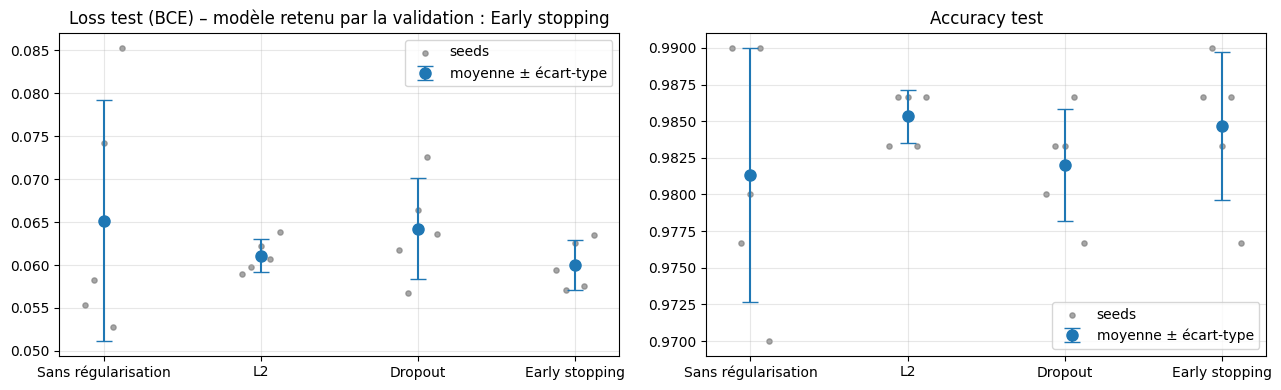

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = list(test_tab.index); xs = np.arange(len(names))
for a, m, sd, t in [(ax[0], "loss_test", "loss_test_std", "Loss test (BCE)"), (ax[1], "acc_test", "acc_test_std", "Accuracy test")]:
    a.errorbar(xs, test_tab[m], yerr=test_tab[sd], fmt="o", capsize=6, ms=8, color="tab:blue", label="moyenne ± écart-type")
    for i, n in enumerate(names):
        a.scatter(np.full(len(SEEDS), i) + np.linspace(-.12, .12, len(SEEDS)), test_df[test_df.cas == n][m],
                  s=14, color="gray", alpha=.7, label="seeds" if i == 0 else None)
    a.set_xticks(xs); a.set_xticklabels(names); a.set_title(t); a.grid(alpha=.3); a.legend()
ax[0].set_title(f"Loss test (BCE) – modèle retenu par la validation : {chosen}")
plt.tight_layout(); fig.savefig("../results/figures/d2_test.png", dpi=150); plt.show()

## Bilan D2


**Sur-apprentissage.** Il est présent sur les 5 seeds sans régularisation. La loss de validation atteint son minimum vers l'époque 127 en moyenne (de 51 à 234 selon la seed), puis remonte pendant que la loss train continue de baisser. L'écart val − train passe d'environ 0.008 à l'époque 50 à 0.037 à l'époque 500. L'accuracy de validation reste presque constante (≈ 0.964) : le sur-apprentissage se voit sur la loss, c'est-à-dire sur la confiance des prédictions, avant de se voir sur l'accuracy.

**Effet de $\lambda$.** Quand $\lambda$ augmente, la norme des poids et l'écart val − train diminuent de façon monotone. L'optimum de validation est à $\lambda = 10^{-3}$. Pour $\lambda \ge 10^{-2}$, la loss train elle-même remonte : le modèle sous-apprend.

**Effet du dropout.** Le dropout réduit l'écart val − train, mais surtout parce que le modèle s'ajuste moins bien au train. Il n'améliore la validation qu'au taux 0.1 et ne réduit pas la norme des poids : il agit autrement que $L^2$.

**Early stopping.** Avec $P = 20$, le modèle est retenu vers l'époque 71 ± 24 (de 46 à 96), après environ 91 époques effectuées sur 500 possibles. Il coûte donc environ 5 fois moins de calcul que les autres cas.

**Test (évalué une seule fois).** La règle posée avant le test retient l'early stopping, de très peu devant $L^2$. Sur le test, le classement est le même que sur la validation, mais les écarts ne sont pas significatifs. Les gains appariés par seed sont d'environ +0.004 à +0.005 de loss pour un écart-type d'environ 0.012, et la régularisation ne fait mieux que sur 2 à 3 seeds sur 5. Sur 300 points, 0.4 point d'accuracy correspond à un seul exemple.

**Ce que la régularisation apporte vraiment ici : la stabilité.** L'écart-type de la loss test entre seeds passe d'environ 0.014 sans régularisation à 0.002 pour $L^2$ et 0.003 pour l'early stopping.

**Limites.** Le test est plus « facile » que la validation : sa loss est plus basse pour tous les modèles. L'écart test − val ne mesure donc pas l'optimisme dû à la sélection sur la validation. Un seul split et des jeux de 300 points limitent aussi les conclusions.